### In this code, I analyse the data to determine efficient way to to store the data in datastore via Zarr

Currently, all the fields are packing inthe same zarr container; which means the boundaries with be largest width, largest height of all the fields. 
This wastes a lot of space, and also creates a hugh chunk that might be time-consuming to process. 


In [49]:
import os
import sys 
print("Active Environment Path:", sys.executable)
from pathlib import Path
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt 
import xarray as xr

import pystac_client
import planetary_computer
import odc.stac
# local
os.chdir("/home/azureuser/EBRD_Tillage/AK_Experiments/AK_pipeline")
sys.path.append(os.getcwd())


Active Environment Path: /anaconda/envs/geospatial-base/bin/python


In [50]:
def check_xarray_nan(obj):
    if isinstance(obj, xr.Dataset):
        return False
    elif pd.isna(obj):  # Handles float('nan'), np.nan, and None safely
        return True
    else:
        raise 
def get_utm_crs(gdf: gpd.GeoDataFrame) -> str:
    """Determine the local UTM EPSG code from a GeoDataFrame centroid."""
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    lon, lat = centroid.x, centroid.y
    zone = int((lon + 180) // 6) + 1
    epsg = 32600 + zone if lat >= 0 else 32700 + zone
    return f"EPSG:{epsg}"
############################################################
def get_sentinel2_STAC(
        geom: shapely.geometry,
        catalog_client: pystac_client.Client, 
        utm_crs: str, 
        input_bands :list, 
        start : str,
        end: str, 
        max_cloud_cover: int = 90,
        resolution: float = 10.0,
    ):
    """Stream optical bands for a single event directly into memory and return
            Object stored as Xarray Dataset. 
            Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
    """

    # 2. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-2-l2a"],
        intersects=geom.__geo_interface__,
        datetime=f"{start}/{end}",
        query={"eo:cloud_cover": {"lte": max_cloud_cover}},
        limit=100
        )
    items = list(search.items())
    if not items:
            return np.nan
    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]

    # 3. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326")
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    # 4. Calculate required bands and stream  directly into an xarray DataArray
    # (xarray chunks/streams directly from Azure Blob Storage COGs)
    xarray_ds = odc.stac.load(
        items,
        bands=input_bands,
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={}
    ).load() # Materialize arrays into RAM

    if xarray_ds.sizes.get("time", 0) == 0:
        return np.nan
        
    # 5. Apply ESA baseline offset correction if needed (>4000 DN)
    for rawband in list(xarray_ds.data_vars): 
        xarray_ds[rawband] = xarray_ds[rawband].astype("float32")

    return xarray_ds
    
    

In [51]:

RUN_ACQUIRE_PATH = Path("/home/azureuser/EBRD_Tillage/EBRD_tillage_monitoring-main/src/acquire/run_acquire.py")  
TEMP_DIR = Path("/home/azureuser/EBRD_Tillage/data/temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DATA_PATH= Path("/home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp")  

In [52]:
print(f"Reading shapefile from: {INPUT_DATA_PATH}")
gdf = gpd.read_file(INPUT_DATA_PATH).drop(columns = ['index'])
gdf=gdf.to_crs("EPSG:4326")
# Quick check
print(f"Successfully loaded {len(gdf)} rows.")
gdf = gdf.rename(columns={'Beginning':'start_date',"End date":'end_date'})
print(gdf.columns)
gdf["start_date"] = pd.to_datetime(gdf["start_date"])
gdf["end_date"] = pd.to_datetime(gdf["end_date"])

utm_crs = get_utm_crs(gdf.iloc[0:1])

gdf

Reading shapefile from: /home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp


Successfully loaded 5746 rows.
Index(['fid', 'Operation', 'Group of o', 'Machinery', 'Machine', 'start_date',
       'end_date', 'Field ID', 'Crop', 'Year', 'Area, ha', 'operation_',
       'source_fil', 'FieldAreaH', 'Completion', 'Classifica', 'geometry'],
      dtype='str')


,fid,Operation,Group of o,Machinery,Machine,start_date,end_date,Field ID,Crop,Year,"Area, ha",operation_,source_fil,FieldAreaH,Completion,Classifica,geometry
0,1.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор CASE IH MAGNUM 315, 14687 АІ; 590-...","Диск.борона LEMKEN RUBIN 9/600 KUA, відсутні...",2020-10-04 06:59:59.999,2020-10-05 06:59:58.999,90.18.10.01.01.05,Corn (2021),2021.0,8.340,Tillage,main,224.819036,0.037097,Conservation,"POLYGON ((34.10441 50.87638, 34.10412 50.87644..."
1,3.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор JOHN DEERE 9460 R, 25881 СВ; 590-1...","Комб.агрегат CASE 335-3 TRUE TANDEM 10,4м, в...",2020-10-06 06:59:59.999,2020-10-07 06:59:58.999,90.18.10.01.01.05,Corn (2021),2021.0,14.888,Tillage,main,224.819036,0.066222,NaN,"POLYGON ((34.10441 50.87638, 34.10412 50.87644..."
2,4.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор JOHN DEERE 9430, 08324 ВІ; 531-101...","Комб.агрегат CASE 330-3 TRUE TANDEM 10,4м; 5...",2020-10-06 06:59:59.999,2020-10-07 06:59:58.999,90.18.10.01.01.05,Corn (2021),2021.0,95.703,Tillage,main,224.819036,0.425689,Conservation,"POLYGON ((34.10441 50.87638, 34.10412 50.87644..."
3,5.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор JOHN DEERE 9460 R, 25881 СВ; 590-1...","Комб.агрегат CASE 335-3 TRUE TANDEM 10,4м, в...",2020-10-05 06:59:59.999,2020-10-06 06:59:58.999,90.18.10.01.01.05,Corn (2021),2021.0,45.686,Tillage,main,224.819036,0.203212,Conservation,"POLYGON ((34.10441 50.87638, 34.10412 50.87644..."
4,6.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор JOHN DEERE 9430, 08324 ВІ; 531-101...","Комб.агрегат CASE 330-3 TRUE TANDEM 10,4м; 5...",2020-10-05 06:59:59.999,2020-10-06 06:59:58.999,90.18.10.01.01.05,Corn (2021),2021.0,59.863,Tillage,main,224.819036,0.266272,Conservation,"POLYGON ((34.10441 50.87638, 34.10412 50.87644..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5741,16687.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор CASE IH STEIGER 600, 29823 СВ; 590...","Комб.агрегат CASE 335-5 TRUE TANDEM 14,3м, в...",2024-05-02 06:59:59.999,2024-05-03 06:59:58.999,90.25.15.36.88.10,Soy (2024),2024.0,25.120,Tillage,main,191.958437,0.130862,Conventional,"MULTIPOLYGON (((32.22299 50.6403, 32.22302 50...."
5742,16688.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор CASE IH STEIGER 600, 33498 СВ; 590...","Комб.агрегат CASE 335-5 TRUE TANDEM 14,3м, в...",2024-05-02 06:59:59.999,2024-05-03 06:59:58.999,90.25.15.36.88.10,Soy (2024),2024.0,21.200,Tillage,main,191.958437,0.110441,Conventional,"MULTIPOLYGON (((32.22299 50.6403, 32.22302 50...."
5743,16689.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор CASE IH STEIGER 600, 29823 СВ; 590...","Комб.агрегат CASE 335-5 TRUE TANDEM 14,3м, в...",2024-05-03 06:59:59.999,2024-05-04 06:59:58.999,90.25.15.36.88.10,Soy (2024),2024.0,82.120,Tillage,main,191.958437,0.427801,NaN,"MULTIPOLYGON (((32.22299 50.6403, 32.22302 50...."
5744,16690.0,Disking to a depth of 5-8 см.,Soil tillage,"Трактор CASE IH STEIGER 600, 33498 СВ; 590...","Комб.агрегат CASE 335-5 TRUE TANDEM 14,3м, в...",2024-05-03 06:59:59.999,2024-05-04 06:59:58.999,90.25.15.36.88.10,Soy (2024),2024.0,66.730,Tillage,main,191.958437,0.347627,NaN,"MULTIPOLYGON (((32.22299 50.6403, 32.22302 50...."


The two mistakes I did previously were - 
 - calculating area directly - instead bounding box area should be calculated DONE 
 - areas were sorted and passed to unsorted df DONE 
 - -- Additionally, UTM issue.  DONE

In [ ]:
buffer_days = 5
input_bands_s2 = ['B04','B08']
# ==============================================================================
# 2.0 CHUNKING FOR MPC CALL
# ==============================================================================
def chunk_df(df, column_name, target_chunk_size):
    """
    Adds '_chunk_bin' and 'chunk_num' columns based on equal-frequency
    quantile binning of a target column.
    """
    df = df.copy()

    # Determine required number of bins
    num_chunks = int(np.ceil(len(df) / target_chunk_size))

    # Assign equal-frequency quantile intervals
    df["_chunk_bin"] = pd.qcut(df[column_name], q=num_chunks, duplicates="drop")

    # Assign integer chunk numbers (0, 1, 2, ...) ordered by the bin intervals
    df["chunk_num"] = df["_chunk_bin"].cat.codes

    return df

def check_xarray_nan(obj):
    if isinstance(obj, xr.Dataset):
        return False
    elif pd.isna(obj):  # Handles float('nan'), np.nan, and None safely
        return True
    else:
        raise 

def find_max_limits(catalog_client, gdf , utm_crs): 
    """
    This function uses a Sentinel 2.
    """
    print(f"Starting in-memory processing for {len(gdf)} tillage events...")
    TARGET_CRS = utm_crs
    feature_datasets = []
    valid_feature_ids = []
    # Run in-memory extraction over events
    band_results = []
    for idx, row in gdf.iterrows():
        index = {'fid_key':row['fid']}
        geom  = row['geometry']
        #start_dt = (pd.to_datetime(row["start_date"]) - pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        start = pd.to_datetime(row["end_date"]).strftime("%Y-%m-%d")
        end = (pd.to_datetime(row["end_date"]) + pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        print(f"Processing Event {idx+1}/{len(gdf)}: {row['fid']}",end="")
        xarray_ds_s2 = get_sentinel2_STAC(geom, catalog_client,utm_crs,input_bands_s2, start,end, max_cloud_cover=90,resolution =10)
        #xarray_ds_s1 = get_sentinel1_STAC(geom, catalog_client, utm_crs, input_bands_s1, start, end, resolution = 10, orbit_direction = None)
        if not check_xarray_nan(xarray_ds_s2):
                current_y, current_x = xarray_ds_s2.sizes["y"], xarray_ds_s2.sizes["x"]
                print(f"---Current y - {current_y}; Current x - {current_x} ")
                yield ('X',current_x, 'Y',current_y)
        else: 
            print('Nan')

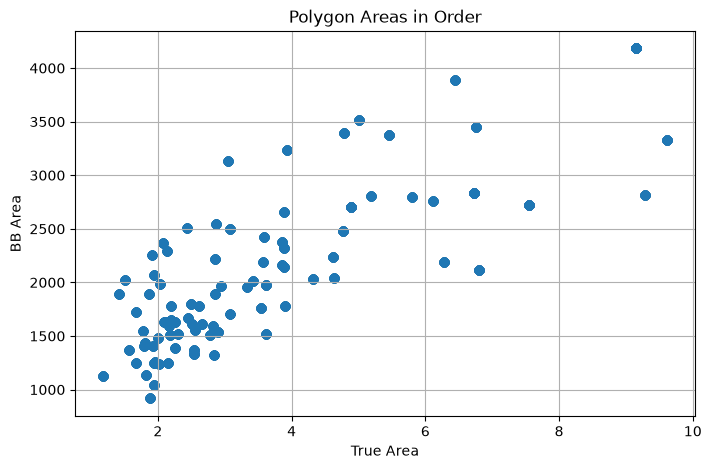

In [54]:
gdf_utm = gdf.to_crs(utm_crs)

#aspect_ratios_x = (gdf_utm.geometry.bounds.apply(lambda b: (b.maxx - b.minx) / (b.maxy - b.miny), axis=1))
#aspect_ratios_y = (gdf_utm.geometry.bounds.apply(lambda b: (b.maxy - b.miny) / (b.maxx - b.minx), axis=1))
#elongation = [max(aspect_ratios_x[i],aspect_ratios_y[i]) for i in range(len(aspect_ratios_x))]

bounds = gdf_utm.geometry.bounds
gdf_utm['width'] = bounds['maxx'] - bounds['minx']
gdf_utm['height'] = bounds['maxy'] - bounds['miny']
gdf_utm['bb_area'] = (gdf_utm['width'] * gdf_utm['height'])/1e6 # Not using gdf.geometry.area as we want axis aligned bounding box area
gdf_utm['geomarea'] = gdf_utm.geometry.area / 1e6
plt.figure(figsize=(8, 5))
plt.scatter(gdf_utm.bb_area, gdf_utm.width)
plt.ylabel("BB Area")
plt.xlabel("True Area")
plt.title("Polygon Areas in Order")
plt.grid(True)
plt.show()

In [55]:
gdf_chunked_utm = chunk_df(gdf_utm, 'bb_area', 200) #[['chunk_num','_chunk_bin']]
gdf_chunked = gdf.copy()  ## Original gdf, unprojected 
gdf_chunked['chunk_num'] = gdf_chunked_utm['chunk_num']
gdf_chunked['_chunk_bin'] = gdf_chunked_utm['_chunk_bin']
gdf_chunked['height_utm'] = gdf_chunked_utm['height']
gdf_chunked['width_utm'] = gdf_chunked_utm['width']
gdf_chunked['bb_area_utm'] = gdf_chunked_utm['bb_area']

del gdf_chunked_utm 



In [82]:
## FINDING THE RIGHT SIZES 
df_lis = []
for num, grp in gdf_chunked.groupby('chunk_num'): 
    maxi = grp[["height_utm", "width_utm", "bb_area_utm"]].idxmax().unique()
    ##maxi = grp[["bb_area_utm"]].idxmax().unique()
    df = grp.loc[maxi]
    assert df['chunk_num'].eq(num).all() 
    df_lis.append(df)

max_df = pd.concat(df_lis,ignore_index=True)
gdf_chunked['_chunk_bin'].value_counts() , max_df.chunk_num.value_counts().value_counts()

(_chunk_bin
 (4.641, 4.895]                 289
 (1.1840000000000002, 1.572]    248
 (1.92, 1.959]                  241
 (2.892, 3.073]                 235
 (1.77, 1.869]                  232
 (2.034, 2.132]                 226
 (2.262, 2.5]                   226
 (2.666, 2.853]                 223
 (2.184, 2.262]                 219
 (3.935, 4.641]                 218
 (6.757, 7.55]                  216
 (5.799, 6.451]                 215
 (6.451, 6.757]                 215
 (3.549, 3.614]                 209
 (3.889, 3.935]                 204
 (3.073, 3.549]                 201
 (2.853, 2.892]                 188
 (3.854, 3.889]                 184
 (9.158, 9.614]                 181
 (2.5, 2.539]                   179
 (2.132, 2.184]                 177
 (2.539, 2.666]                 171
 (1.869, 1.92]                  163
 (1.572, 1.77]                  159
 (5.192, 5.799]                 155
 (1.959, 2.034]                 151
 (7.55, 9.158]                  147
 (4.895, 5.192] 

In [ ]:
catalog_client = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace
    )

done = True 
max_limits = []
if(not done):
    for grpnum, grp in max_df.groupby('chunk_num'):
        print('Group --' , grpnum," ",end = '')
        #xarray_ds_s2 = find_max_limits(catalog_client, grp , utm_crs)
        vals = find_max_limits(catalog_client, grp , utm_crs)
        print(grpnum, [*vals])
        max_limits.append( [grpnum]+ [*vals])
else:
    max_limits = {0 :( 207,  80),1 :( 161,  140), 2 :( 194,  166),
3 :( 231,  211),4 :( 212,  191), 5 :( 204,  169),6 :( 242,  135),
7 :( 164,  177),8 :( 183,  168), 9 :( 256,  157),10 :( 166,  195),
11 :( 183,  170),12 :( 227,  220), 13 :( 259,  193), 14 :( 318,  185),
15 :( 181,  206),16 :( 248,  187),17 :( 242,  244),18 :( 271,  183), 
19 :( 328,  224), 20 :( 229,  233), 21 :( 344,  197), 22 :( 357,  190), 
23 :( 342,  212), 24 :( 394,  292),25 :( 350,  243),26 :( 277,  327), 
27 :( 423,  224),28 :( 338,  335)}

## for the Nans 
done = True 
if(not done):
    indices = [1,9,21]
    max_limits_2 = []
    for index in indices: 
        grp = gdf_chunked[gdf_chunked.chunk_num == index]
        grp_sorted = grp.sort_values(by = ['bb_area_utm']).iloc[0:3]
        vals = find_max_limits(catalog_client, grp_sorted , utm_crs)
        max_limits_2.append( [index]+ [*vals])
max_limits_2 

Group -- 0  Starting in-memory processing for 2 tillage events...
Processing Event 1/2: 8759.0Nan
Processing Event 2/2: 1443.0---Current y - 80; Current x - 207 
0 [('X', 207, 'Y', 80)]
Group -- 1  Starting in-memory processing for 3 tillage events...
Processing Event 3/3: 5894.0---Current y - 140; Current x - 130 
Processing Event 4/3: 14929.0Nan
Processing Event 5/3: 12507.0---Current y - 119; Current x - 161 
1 [('X', 130, 'Y', 140), ('X', 161, 'Y', 119)]
Group -- 2  Starting in-memory processing for 2 tillage events...
Processing Event 6/2: 7816.0---Current y - 166; Current x - 118 
Processing Event 7/2: 9137.0---Current y - 104; Current x - 194 
2 [('X', 118, 'Y', 166), ('X', 194, 'Y', 104)]
Group -- 3  Starting in-memory processing for 3 tillage events...
Processing Event 8/3: 8416.0---Current y - 211; Current x - 97 
Processing Event 9/3: 4481.0---Current y - 89; Current x - 231 
Processing Event 10/3: 15936.0---Current y - 141; Current x - 146 
3 [('X', 97, 'Y', 211), ('X', 231

[[1, ('X', 178, 'Y', 101), ('X', 178, 'Y', 101), ('X', 178, 'Y', 101)],
 [9, ('X', 156, 'Y', 157), ('X', 156, 'Y', 157), ('X', 156, 'Y', 157)],
 [21, ('X', 253, 'Y', 197), ('X', 253, 'Y', 197), ('X', 253, 'Y', 197)]]

In [2]:

#CAREFUL! 
from adlfs import AzureBlobFileSystem
from azure.identity import DefaultAzureCredential
from azure.ai.ml import MLClient


ml_client = MLClient.from_config(credential=DefaultAzureCredential())
datastore_name = "rise_data"
datastore = ml_client.datastores.get(datastore_name)
account_name = datastore.account_name
container_name = datastore.container_name
relative_path = "abhi/TillageClassification/"


done = False
if(not done): 
    # Initialize the filesystem
    fs = AzureBlobFileSystem(
        account_name=account_name,
        credential=DefaultAzureCredential()
    )

    # Target folder path (Zarr store)
    target_path = f"{container_name}/{relative_path}20261006__TillageDataset__Chunk1"
    print(target_path)
    # Delete the Zarr dataset folder recursively
    ##fs.rm(target_path, recursive=True)

    # 1. Find all underlying chunk/metadata files inside the Zarr directory
    files_to_delete = fs.find(target_path)
    print(files_to_delete)
    
    # 2. Delete all individual files
    if files_to_delete:
        fs.rm(files_to_delete)
    
    # 3. Clean up the now-empty parent directory
    if fs.exists(target_path):
        fs.rmdir(target_path , recursive=True)
    
    

Found the config file in: /config.json


data/abhi/TillageClassification/20261006__TillageDataset__Chunk1
['data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/0/0', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/0/1', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/0/2', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/0/3', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/1/0', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/1/1', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/1/2', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/1/3', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/2/0', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/2/1', 'data/abhi/TillageClassification/20261006__TillageDataset__Chunk1/B02/c/0/0/2/2', 'data/abhi/TillageClassification